# Проект. Исследование стартапов

## Введение

Поле для вашего введения: опишите контекст и цели проекта. Чтобы изменить содержимое ячейки, дважды нажмите на неё или нажмите «Ввод».

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `data/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [ ]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("data/cb_investments.zip", sep=';', low_memory=False)`

In [ ]:
df_inv = pd.read_csv("data/cb_investments.zip", sep=';', low_memory=False)
df_ret = pd.read_csv("data/cb_returns.csv", sep=',', low_memory=False)

Выведите информацию, которая необходима для принятия решений о предобработке.

Познакомимся с основным датафреймом

In [3]:
#Выведем первые 10 строк
df_inv[['funding_rounds', 'participants', 'founded_year']].head(10)

,funding_rounds,participants,founded_year
0,1.0,NaN,1636.0
1,1.0,NaN,1785.0
2,1.0,1.0,1802.0
3,3.0,0.0,1817.0
4,1.0,NaN,1826.0
5,1.0,NaN,1831.0
6,4.0,0.0,1834.0
7,1.0,NaN,1838.0
8,1.0,NaN,1838.0
9,2.0,2.0,1840.0


In [4]:
#Выведем основную информацию о датафрейме
df_inv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Датафрейм состоит из 54 294 строк и 39 столбцах.
24 столбца содержат данные типа float64, а 16 столбцов - типа object.
Все столбцы содержат пропуски. Столбцы 4, 10, 16 и группа столбцов с 18 по 39 содержат одинаковое количество непустых строк.

Для оптимизации типов данных нужно запланировать следующие корректировки:
* `funding_total_usd` - привести к типу **float64**
* `funding_rounds` — Привести к типу **int8**, т.к количество раундов не может быть не целым числом
* `participants` — Привести к типу **int8**, т.к число участников не может быть вещественным типом
* `founded_at` — дата основания компании. Приведем к типу **datetime**
* `founded_year` — год основания. Можем сократить разрядность и привести к целомучисленному типу **int16**
* `first_funding_at` — дата первого финансирования. Приведем к **datetime**
* `mid_funding_at` — дата среднего по времени раунда финансирования. Приведем к **datetime**
* `last_funding_at` — дата последнего финансирования. Приведем к **datetime**

Познакомимся с дополнительным датасетом `cb_returns.csv`

In [5]:
df_ret.head(50)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [6]:
df_ret.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет содержит 15 строк и 14 столбцов. 
13 столбцов содержат данные типа float64, столбец year - тип int64. Типы данных назначены корректно.
Все столбцы не содержат пустых значений

In [7]:
#Сохраним исходное количество строк в датасете
start_value_counts = df_inv.shape[0]
print(start_value_counts)

54294


Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

Основной датасет df_inv содержит 54 294 записи и 40 столбцов.
Пропуски: Данные содержат значительное количество пропусков. Особенно много их в столбцах, связанных с географией (state_code, city) и датой основания (founded_at). Это нужно будет учесть при анализе. Критически важный столбец funding_total_usd также имеет пропуски, которые необходимо будет обработать.


Типы данных:
1. Столбцы с датами (founded_at, first_funding_at и др.) имеют тип object, их необходимо преобразовать в datetime для корректной работы с датами.
2. Столбец funding_total_usd также имеет тип object из-за наличия символов-разделителей (пробелов). Его нужно привести к числовому типу.

Названия столбцов: 

1. В некоторых названиях столбцов (например, market) присутствуют лишние пробелы, что может привести к ошибкам. Необходимо привести все названия к единому стилю.
2. Дополнительный датасет df_ret содержит 15 строк и 14 столбцов. Пропусков в нем нет, типы данных корректны. Важно помнить, что суммы в нем указаны в миллионах долларов.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [8]:
#Выведем список всех столбцев
print(df_inv.columns)
print(df_ret.columns)

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')
Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')


В столбцах ' market ' и ' funding_total_usd ' содержатся пробелы в начале и в конце, можно обработать названия.
Названия раундов инвестирования можно привести к snake_case для единообразия  
К столбцам в датасете cb_returns можно добавить метку **r_**, чтобы не спутать с идентичными названиями в основном датасете

In [9]:
# Удалим лишние пробелы в названиях столбцов и приведем все столбцы к нижнему регистру
df_inv = df_inv.rename(columns=lambda x: x.strip().lower())
df_inv.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [10]:
#Заменим лишние символы в столбце и приведем к числовому типу
df_inv['funding_total_usd'] = pd.to_numeric(
    df_inv['funding_total_usd'].astype(str).str.replace(r"[^\d\.-]", "", regex=True), 
    errors='coerce')
print(df_inv['funding_total_usd'].head(10))

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
5    19000000.0
6    12000000.0
7     8700000.0
8     6000000.0
9     3500000.0
Name: funding_total_usd, dtype: float64


Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [11]:
#Приведем столбцы с датами к типу datetime
for column in ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']:
    df_inv[column] = pd.to_datetime(df_inv[column], errors='coerce')
print(df_inv.dtypes)

name                            object
homepage_url                    object
category_list                   object
market                          object
funding_total_usd              float64
status                          object
country_code                    object
state_code                      object
region                          object
city                            object
funding_rounds                 float64
participants                   float64
founded_at              datetime64[ns]
founded_month                   object
founded_quarter                 object
founded_year                   float64
first_funding_at        datetime64[ns]
mid_funding_at          datetime64[ns]
last_funding_at         datetime64[ns]
seed                           float64
venture                        float64
equity_crowdfunding            float64
undisclosed                    float64
convertible_note               float64
debt_financing                 float64
angel                    

In [12]:
#Преобразуем значения в столбцах в целочисленный тип данных. Дополнительно заменим пропуски на индикатор
for column in ['funding_rounds', 'participants', 'founded_year']:
    df_inv[column] = pd.to_numeric(df_inv[column].fillna(-1), downcast='integer', errors='coerce')
#Выведем скорректированные типы данных
print(df_inv[['funding_rounds', 'participants', 'founded_year', 'founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].dtypes)

funding_rounds                int8
participants                  int8
founded_year                 int16
founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object


В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [13]:
#Сделаем столбец year индексом всего датасета cb_returns
df_ret = df_ret.set_index('year')
df_ret.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [14]:
#Проверяем уникальные значения в столбцах
for column in [ 'market', 'status', 'country_code', 'state_code']:
    print(f'Уникальные значения в столбце {column}:')
    print(df_inv[column].sort_values().unique())
    print()

Уникальные значения в столбце market:
[' 3D' ' 3D ' ' 3D Printing ' ' 3D Technology ' ' Ad Targeting '
 ' Advanced Materials ' ' Adventure Travel ' ' Advertising'
 ' Advertising ' ' Advertising  ' ' Advertising Networks '
 ' Advertising Platforms ' ' Advice ' ' Aerospace ' ' Agriculture '
 ' Algorithms ' ' All Students ' ' Alternative Medicine ' ' Analytics'
 ' Analytics ' ' Analytics  ' ' Android' ' Android ' ' Animal Feed '
 ' App Marketing ' ' App Marketing  ' ' App Stores '
 ' Application Platforms ' ' Apps' ' Apps ' ' Apps  ' ' Art '
 ' Artificial Intelligence' ' Artificial Intelligence '
 ' Artists Globally ' ' Assisitive Technology ' ' Auctions ' ' Audio '
 ' Augmented Reality ' ' Automotive' ' Automotive ' ' Automotive  '
 ' B2B ' ' Baby Accessories ' ' Banking ' ' Batteries ' ' Beauty '
 ' Bicycles ' ' Big Data' ' Big Data ' ' Big Data Analytics'
 ' Big Data Analytics ' ' Biotechnology' ' Biotechnology '
 ' Biotechnology  ' ' Bitcoin ' ' Blogging Platforms ' ' Brand Marketing'

Можно увидеть, что в столбце Market встречаются неявные дубликаты, связанные с пробелами

In [ ]:
#Проверим и удалим пробелы в начале и в конце строки. Заполним пропуски
for column in ['name', 'homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']:
    df_inv[column] = df_inv[column].str.strip().fillna('')

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [16]:
# Проверяем полные дубликаты в датафрейме df_inv
print(df_inv.duplicated().sum())

4855


In [17]:
# Удаляем полные дубликаты в датафрейме df_inv
df_inv = df_inv.drop_duplicates(keep=False)
#Повторно проверим количество полных дубликатов
df_inv.duplicated().sum()

0

In [ ]:
#Удалим пропуски в столце 'funding_total_usd'
df_inv = df_inv.dropna(subset=['funding_total_usd'])

In [19]:
#Сохраним количество строк после обработки
final_row_count = df_inv.shape[0]
print(final_row_count)

40907


In [ ]:
#Добавим в столбцы с месяцем и кварталом данные из столбца founded_at
df_inv['founded_month'] = df_inv['founded_at'].dt.month
df_inv['founded_quarter'] = df_inv['founded_at'].dt.quarter

Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [ ]:
# Заполняем пропуски средним значением
mean_date = (df_inv['first_funding_at'] + (df_inv['last_funding_at'] - df_inv['first_funding_at']) / 2)
df_inv['mid_funding_at'] = df_inv['mid_funding_at'].fillna(mean_date)

In [22]:
#Посчитаем количество пропусков в столбце
print('Пропуски в столбце mid_funding_at')
print(df_inv['mid_funding_at'].isna().sum())

Пропуски в столбце mid_funding_at
1


Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [23]:
#Посчитаем итоговое количество пропусков в столбцах
print('Пропуски')
print(df_inv.isna().sum())
# Подсчитываем долю строк с пропусками
df_inv.isna().sum() / df_inv.shape[0]

Пропуски
name                       0
homepage_url               0
category_list              0
market                     0
funding_total_usd          0
status                     0
country_code               0
state_code                 0
region                     0
city                       0
funding_rounds             0
participants               0
founded_at              8707
founded_month           8707
founded_quarter         8707
founded_year               0
first_funding_at           2
mid_funding_at             1
last_funding_at            0
seed                       0
venture                    0
equity_crowdfunding        0
undisclosed                0
convertible_note           0
debt_financing             0
angel                      0
grant                      0
private_equity             0
post_ipo_equity            0
post_ipo_debt              0
secondary_market           0
product_crowdfunding       0
round_a                    0
round_b                    0
round

name                    0.000000
homepage_url            0.000000
category_list           0.000000
market                  0.000000
funding_total_usd       0.000000
status                  0.000000
country_code            0.000000
state_code              0.000000
region                  0.000000
city                    0.000000
funding_rounds          0.000000
participants            0.000000
founded_at              0.212849
founded_month           0.212849
founded_quarter         0.212849
founded_year            0.000000
first_funding_at        0.000049
mid_funding_at          0.000024
last_funding_at         0.000000
seed                    0.000000
venture                 0.000000
equity_crowdfunding     0.000000
undisclosed             0.000000
convertible_note        0.000000
debt_financing          0.000000
angel                   0.000000
grant                   0.000000
private_equity          0.000000
post_ipo_equity         0.000000
post_ipo_debt           0.000000
secondary_

In [24]:
#Расчитаем количество удаленных значений
deleted = start_value_counts - final_row_count

#Выведем все изменения
print(f'Всего строк в стартовом датасете: {start_value_counts}')
print(f'Всего строк в обработанном датасете: {final_row_count}')
print(f'Всего удалено строк: {deleted}')
print(f'Доля удаленных строк: {round((deleted / start_value_counts) * 100, 2)}%')

Всего строк в стартовом датасете: 54294
Всего строк в обработанном датасете: 40907
Всего удалено строк: 13387
Доля удаленных строк: 24.66%


In [ ]:
#Скорректируем общее финансирование в миллионы
df_inv['funding_total_usd'] = df_inv['funding_total_usd']/1_000_000

Были выполнены все необходимые шаги предобработки: названия столбцов приведены к единому стилю, исправлены типы данных для дат и сумм финансирования, обработаны дубликаты.
Пропуски в ключевом столбце funding_total_usd были удалены, так как строки без информации о сумме финансирования не несут ценности для нашего исследования.
Пропуски в mid_funding_at были успешно заполнены на основе дат первого и последнего раундов, что позволит нам проводить анализ по годам.
В ходе предобработки было удалено 13 387 строк, что составляет 24.66% от исходного датасета. Это полные дубликаты и пропуски в столбцах финасирования. На выходе имеем корректный датасет для анализа

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [26]:
#Создадим функцию для категоризации сроков инвестирования
def categorize_fund(value):
    if value['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif (value['last_funding_at'] - value['first_funding_at']) / pd.to_timedelta('1 D') < 365:
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'
#Создадим новый столбец на основе функции
df_inv['category_funding'] = df_inv.apply(categorize_fund, axis=1)
print(df_inv['category_funding'])

0           Единичное финансирование
1           Единичное финансирование
2           Единичное финансирование
3        Срок финансирования до года
4           Единичное финансирование
                    ...             
49433       Единичное финансирование
49434       Единичное финансирование
49435       Единичное финансирование
49436       Единичное финансирование
49437       Единичное финансирование
Name: category_funding, Length: 40907, dtype: object


In [27]:
#Создадим переменную для расчета долей по количеству компаний в каждой категории финансирования
count_funding = df_inv['category_funding'].value_counts(normalize=True)
print(count_funding)

Единичное финансирование          0.589459
Срок финансирования более года    0.302809
Срок финансирования до года       0.107732
Name: category_funding, dtype: float64


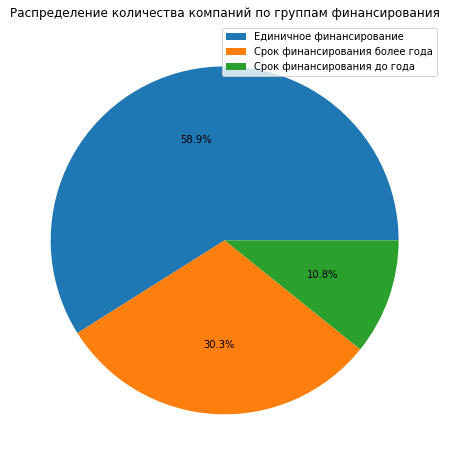

In [28]:
#Создадим круговую диаграмму по количеству компаний в каждой категории финансирования
plt.figure(figsize=(10, 8))
count_funding.plot(
    kind='pie', 
    title='Распределение количества компаний по группам финансирования', 
    autopct='%1.1f%%',
    labels=None,
    ylabel='',
    legend=True
)
plt.show()

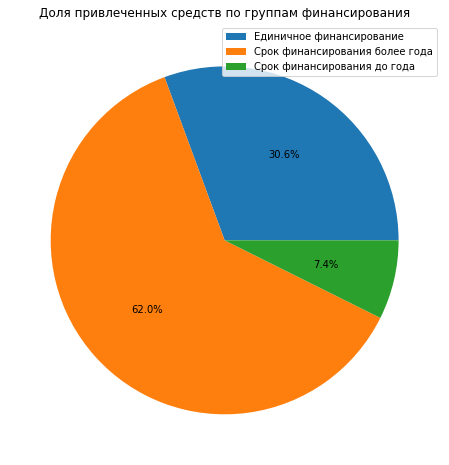

In [29]:
#Построим круговую диаграмму на основе суммы инвестиций по каждой категории
plt.figure(figsize=(10, 8))
df_inv.groupby('category_funding')['funding_total_usd'].sum().plot(
    kind='pie',
    title= 'Доля привлеченных средств по группам финансирования',
    autopct='%1.1f%%',
    labels=None,
    ylabel='',
    legend=True
)
plt.show()

Сравнение двух диаграмм показывает:

По количеству преобладают компании с единичным финансированием (58.9%). Это типичная "воронка" стартапов: многие получают первый раунд, но немногие двигаются дальше.
По объему инвестиций картина обратная: основную долю средств (62.3%) привлекают компании, которые финансируются более года.
Это говорит о том, что инвесторы "голосуют деньгами" за долгосрочные и проверенные проекты. Основной капитал концентрируется в компаниях, которые смогли доказать свою жизнеспособность и пройти несколько раундов финансирования.


### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [30]:
#Создадим переменную в которой заранее отфильтруем пустые строки и посчитаем количество строк в столбце market
market_counts = df_inv[df_inv['market']!= '']['market'].value_counts()

#Создадим переменную с индексами из массовых сегментов
massive_markets_list = market_counts[market_counts > 120].index
#Создадим переменную с индексами из средних сегментов
mid_markets_list = market_counts[(market_counts > 35)&(market_counts <= 120)].index

#Создадим функцию где назначим категории в зависимости от сегмента
def categorize_market(row):
    market_name = row['market']
    if market_name in massive_markets_list: 
        return 'Массовый'
    elif market_name in mid_markets_list:
        return 'Средний'
    else:
        return 'Нишевый'
#Создадим новый столбец category_market на основе функции
df_inv['category_market'] = df_inv.apply(categorize_market, axis=1)
display(df_inv['category_market'])

0        Массовый
1         Нишевый
2         Средний
3        Массовый
4        Массовый
           ...   
49433     Нишевый
49434     Нишевый
49435     Нишевый
49436     Нишевый
49437    Массовый
Name: category_market, Length: 40907, dtype: object

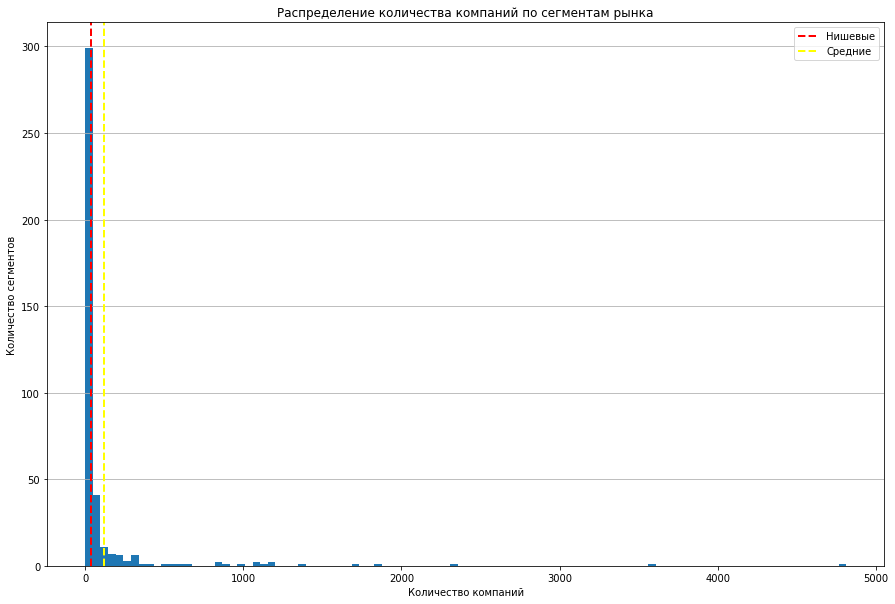

In [31]:
#Построим гистрограмму на основе количеста сегментов
plt.figure(figsize=(15,10))
market_counts.hist(bins=100)

#Добавим линии на нишевые и средние сегменты
plt.axvline(x=35,
            color='red',
            linestyle='--',
            linewidth=2,
            label='Нишевые')
plt.axvline(x=120,
            color='yellow',
            linestyle='--',
            linewidth=2,
            label='Средние')
plt.title('Распределение количества компаний по сегментам рынка')
plt.grid(axis='x')
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.legend()
plt.show()

Гистограмма распределения размеров рынков демонстрирует сильную асимметрию вправо. Подавляющее большинство рынков являются "нишевыми" (содержат до 35 компаний), и лишь небольшое количество — "массовыми". Это подтверждает гипотезу о том, что рынок стартапов состоит из огромного числа мелких ниш и нескольких крупных, популярных направлений.

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [ ]:
#Заменим значения по нишевым и средним сегментам на заглушки
df_inv.loc[df_inv['category_market']  == 'Нишевый', 'market'] = 'niche'
df_inv.loc[df_inv['category_market']  == 'Средний', 'market'] = 'mid'

Алексей, привет. Можно ли было решить вопрос по средним и нишевым клиентам (строчка 29) с помощью pd.cut? Не смог найти работающий подход без создания переменных

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

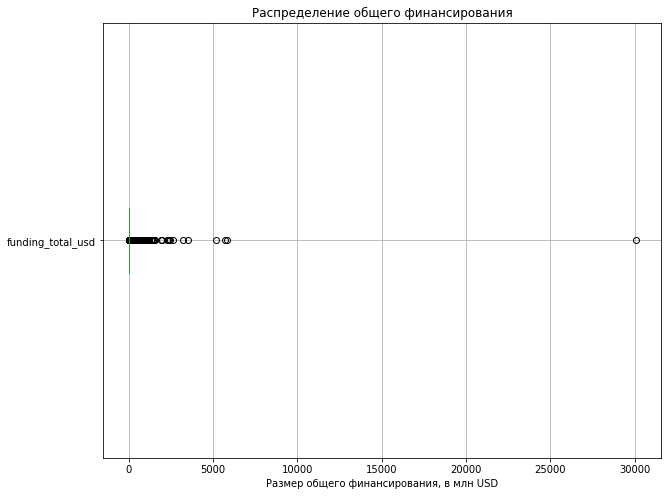

In [33]:
#Построим ящик с усами
boxplot = df_inv.boxplot(column = 'funding_total_usd',
        vert=False,
        figsize=(10,8))
boxplot.set_title('Распределение общего финансирования')
boxplot.set_xlabel('Размер общего финансирования, в млн USD')
plt.show()

Диаграмма размаха для funding_total_usd показывают, что данные сильно смещены вправо из-за наличия компаний с аномально высоким финансированием (выбросов).

In [34]:
#Выведем 95 квантиль, чтобы сделать график читаемым
df_inv['funding_total_usd'].quantile(0.95)


60.0

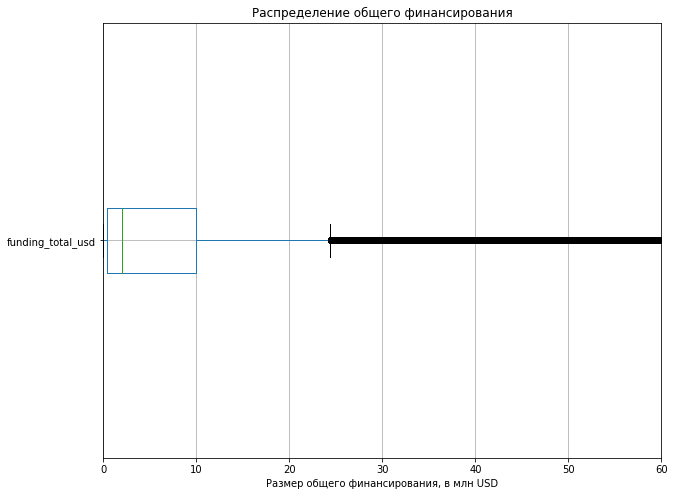

In [35]:
#Построим ящик с усами до 95-го квантиля
boxplot = df_inv.boxplot(column = 'funding_total_usd',
        vert=False,
        figsize=(10,8))
boxplot.set_title('Распределение общего финансирования')
boxplot.set_xlabel('Размер общего финансирования, в млн USD')
plt.xlim(0,60)
plt.show()

Видим что 75% всех инвестиций находятся в диапазоне до 10 млн долларов

In [36]:
#Дополнительно используем метод describe
df_inv['funding_total_usd'].describe()

count    40907.000000
mean        15.912526
std        168.678800
min          0.000001
25%          0.350000
50%          2.000000
75%         10.000000
max      30079.503000
Name: funding_total_usd, dtype: float64

Спасибо, привел значения в миллионы последней строчкой на этапе предобработки. Все графики скорректировал под млн

Типичные значения лежат в интервале от 350 000 долларов до 10 000 000 долларов. 
Типичный интервал финансирования для 50% компаний (межквартильный размах) лежит между $350 тыс. (Q1) и $10 млн (Q3).
Медианное значение составляет $2 млн, что является более показательной мерой центра, чем среднее ($15.9 млн), которое сильно завышено из-за выбросов.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [ ]:
#Создадим функцию, которая будет получать название сегмента, 
#считать квантили, IQR и верхний порог для выбросов
def calculate_upper_bound(segment_name):
    quantile_75 = df_inv[df_inv['category_market']==(segment_name)]['funding_total_usd'].quantile(0.75)
    quantile_25 = df_inv[df_inv['category_market']==(segment_name)]['funding_total_usd'].quantile(0.25)
    iqr = quantile_75 - quantile_25
    upper_bound =  quantile_75  + 1.5 *  iqr
    return upper_bound
upper_mass = calculate_upper_bound('Массовый')
upper_mid = calculate_upper_bound('Средний')
upper_niche = calculate_upper_bound('Нишевый')

In [ ]:
#Создадим булевую маску для нового столбца, куда будем подставлять значения на основе категории
# и сравнения финансирования с рассчитанным верхним порогом 
df_inv['is_outlier'] = (
    (df_inv['category_market'] == 'Массовый') & (df_inv['funding_total_usd'] > upper_mass) |
    (df_inv['category_market'] == 'Средний') & (df_inv['funding_total_usd'] > upper_mid) |
    (df_inv['category_market'] == 'Нишевый') & (df_inv['funding_total_usd'] > upper_niche)
)

In [39]:
#Группируем по рынкам и считаем сумму выбросов и общее количество строк
outlier_stats = df_inv.groupby('market')['is_outlier'].agg(['sum', 'count'])
#Определяем долю
share_outlier_stats = (outlier_stats['sum']/outlier_stats['count'])*100
#Сортируем и выводим топ10 категорий
display(share_outlier_stats.sort_values(ascending=False).head(10))

market
Semiconductors         31.404959
Clean Technology       26.949153
Health Care            26.582278
Web Hosting            24.528302
Technology             24.369748
Biotechnology          22.311978
Cloud Computing        16.447368
Security               16.225750
Enterprise Software    15.496017
Networking             14.685315
dtype: float64

Наибольшая доля компаний с аномально высоким финансированием наблюдается в сложных и капиталоемких отраслях, таких как Semiconductors (Полупроводники) и Clean Technology (Чистые технологии). Вероятно это связано с тем, что разработка в этих сферах требует значительно больших первоначальных вложений, долгий возврат и высокие риски.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

В качестве оценки полноты данных возьмем столбец 'last_funding_at' и найдем последнюю дату

In [40]:
df_inv['last_funding_at'].max()

Timestamp('2014-12-31 00:00:00')

Последняя запись в столбце датируется '2014-12-31 00:00:00', что может говорить о полноте данных за год

In [ ]:
#Оставим в датафрейме данные без выбросов
df_inv = df_inv[df_inv['is_outlier'] == 0]

In [42]:
#Выделим года из даты в отдельный столбец
df_inv.loc[:, 'mid_funding_year'] = df_inv['mid_funding_at'].dt.year
#Создадим переменную в которой сгруппируем года и посчитаем сумму раундов по каждому году
rounds_per_year = df_inv.groupby('mid_funding_year')['funding_rounds'].sum()
#Выделим индексы тех строк в которых сумма раундов была больше или равна 50        
active_years = rounds_per_year[rounds_per_year >= 50].index
#Оставим в дата фрейме только те строки, годы которые есть в переменной active_years  
df_inv = df_inv[df_inv['mid_funding_year'].isin(active_years)]
display(active_years)

Float64Index([1999.0, 2000.0, 2001.0, 2002.0, 2003.0, 2004.0, 2005.0, 2006.0,
              2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0],
             dtype='float64', name='mid_funding_year')

Проверка показала, что данные за 2014 год являются полными, так как последняя дата финансирования в датасете — 31 декабря 2014 года.
Из датасета были исключены компании с аномальными объемами финансирования, чтобы они не искажали дальнейший анализ динамики.
Период исследования был ограничен годами, в которые наблюдалась высокая инвестиционная активность (50 и более раундов в год)

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

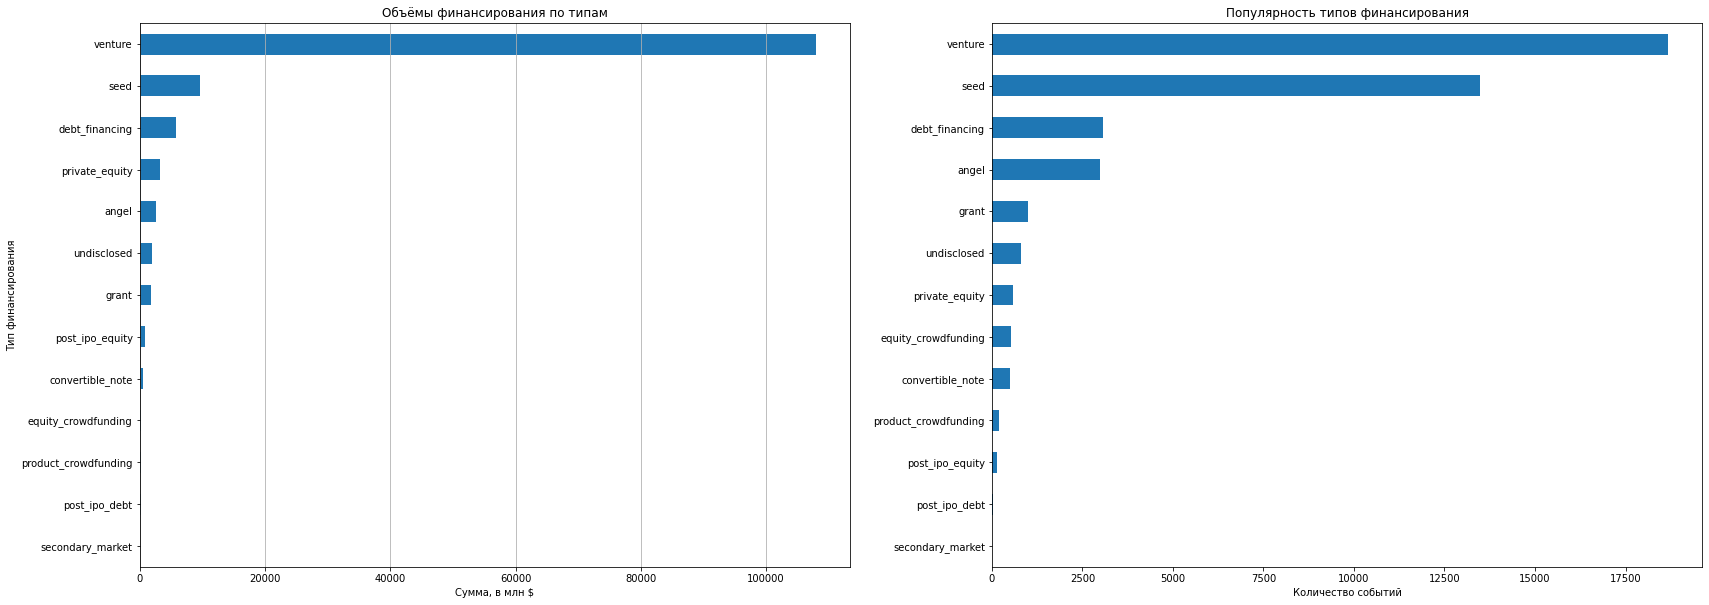

In [43]:
#Создадим полотно для отображения двух графиков рядом
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(28, 10))

#Посчитаем сумму инвестиций по нужным столбцам
total_funding = df_inv[['seed', 'venture', 'equity_crowdfunding', 
                        'undisclosed', 'convertible_note', 'debt_financing', 
                        'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                        'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum().sort_values(ascending=True)/1_000_000
#Посчитаем количество событий (Сумма больше 0 в строке говорит о том, что тип инвестиций использовался). 
popularity = (df_inv[['seed', 'venture', 
                     'equity_crowdfunding', 'undisclosed', 
                     'convertible_note', 'debt_financing', 'angel', 
                     'grant', 'private_equity', 'post_ipo_equity', 
                     'post_ipo_debt', 'secondary_market', 'product_crowdfunding']] > 0).sum().sort_values(ascending=True) 

#Создаем круговую диаграмму по сумме инвестиций
total_funding.plot(kind='barh', ax=axes[0])
axes[0].set_title('Объёмы финансирования по типам')
axes[0].set_xlabel('Сумма, в млн $')
axes[0].set_ylabel('Тип финансирования')
axes[0].grid(axis='x')

#Создаем круговую диаграмму по количеству событий типов финансирования
popularity.plot(kind='barh', ax=axes[1])
axes[1].set_title('Популярность типов финансирования')
axes[1].set_xlabel('Количество событий')


plt.show()

Лидеры рынка: Венчурное (venture) и посевное (seed) финансирование являются безусловными лидерами как по суммарному объему привлеченных средств, так и по частоте использования.
Частые, но небольшие: Ангельские (angel) инвестиции очень популярны (4-е место по частоте), но характеризуются небольшими средними чеками
Редкие, но крупные: Прямые частные инвестиции (private_equity) используются редко, но предполагают очень крупные вложения

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

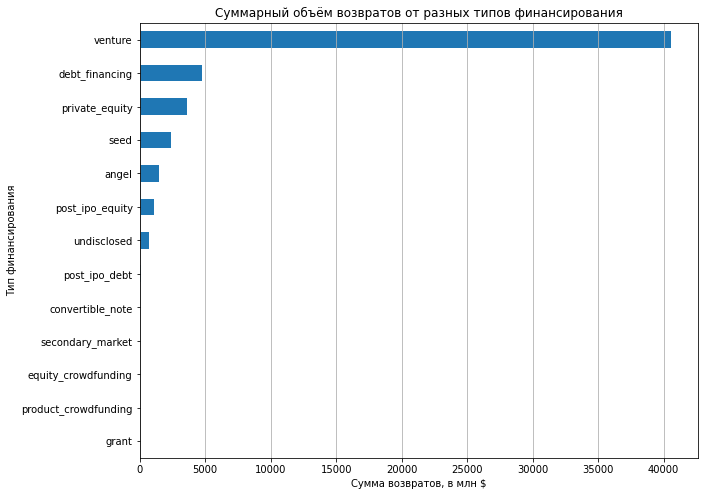

In [44]:
#Считаем сумму возвратов во втором датафрейме
total_returns_scaled = (df_ret.sum().sort_values(ascending=True))
# Строим график
plt.figure(figsize=(10,8))
total_returns_scaled.plot(
    kind='barh'
)

plt.title('Cуммарный объём возвратов от разных типов финансирования')
plt.xlabel('Сумма возвратов, в млн $')
plt.ylabel('Тип финансирования')
plt.grid(axis='x')

plt.show()

Возвраты: По суммарному объему возвратов также лидирует венчурное финансирование, что логично, так как в него было больше всего вложено. Однако, простое сравнение сумм вложений и возвратов показывает, что венчурный бизнес — это долгосрочная игра, и возврат инвестиций происходит далеко не сразу.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

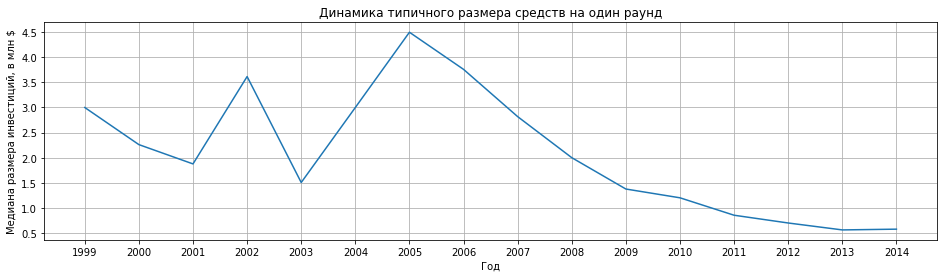

In [45]:
plt.figure(figsize=(16,4))
#Создаем столбец со средней суммой инвестиций на один раунд (отношение суммы к количеству)
df_inv['avg_round_funding']  = (df_inv['funding_total_usd'] / df_inv['funding_rounds'])
#Создаем переменную где отобразим медиану по среднему количеству инвестиций на раунд по каждому году
round_agg = df_inv.groupby('mid_funding_year')['avg_round_funding'].median()

#Рисуем график
round_agg.plot(kind='line')
plt.title('Динамика типичного размера средств на один раунд')
plt.xlabel('Год')
plt.ylabel('Медиана размера инвестиций, в млн $')
plt.grid()
plt.xticks(round_agg.index)
plt.show()

In [46]:
print(round_agg.sort_values(ascending=False))

mid_funding_year
2005.0    4.500000
2006.0    3.760000
2002.0    3.616667
1999.0    3.000000
2004.0    3.000000
2007.0    2.818292
2000.0    2.260234
2008.0    2.000000
2001.0    1.875530
2003.0    1.505000
2009.0    1.375000
2010.0    1.200000
2011.0    0.852671
2012.0    0.698000
2014.0    0.575000
2013.0    0.560000
Name: avg_round_funding, dtype: float64


В 2005 году типичный размер средств на один раунд находился на максимальном уровне

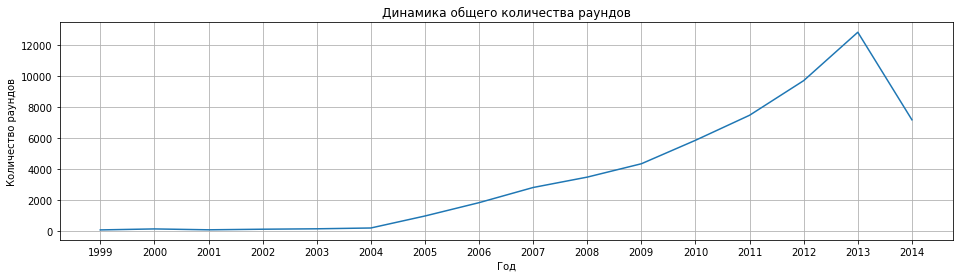

In [47]:
plt.figure(figsize=(16,4))
#Считаем сумму раундов на каждый год
round_sum = df_inv.groupby('mid_funding_year')['funding_rounds'].sum()

#Строим график
round_sum.plot(kind='line')
plt.title('Динамика общего количества раундов')
plt.xlabel('Год')
plt.ylabel('Количество раундов')
plt.grid()
#Добавим гранулярности по годам
plt.xticks(round_sum.index)
plt.show()

В 2014 году заметно относительно прошлого года снизилось количество раундов (7159 раундов), а сумма инвестиций выросла до 575 000 $ (+110 000$ YoY) 

Общее количество раундов резко сократилось по сравнению с пиковым 2013 годом, однако типичный размер одного раунда немного вырос. Это может свидетельствовать о том, что инвесторы стали более избирательными, предпочитая вкладывать большие суммы в меньшее количество более надежных проектов.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [48]:
#Создаем сводную по категориям, годам и сумме инвестиций
pivot_funding = pd.pivot_table(df_inv,
                             index='market',
                             columns='mid_funding_year',
                             values='funding_total_usd',
                             aggfunc="sum",
                             fill_value = 0)
#Фильтруем сводную по условию что 2014 больше 2014 по сумму 
#и оставляем только массовый сегмент из переменной massive_markets_list из шага 2.2
filtered = pivot_funding[(pivot_funding[2014] > pivot_funding[2013]) & (pivot_funding.index.isin(massive_markets_list)) ]
display(filtered)

mid_funding_year,1999.0,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0
market,,,,,,,,,,,,,,,,
Apps,0.00,0.0,0.00,0.000,0.0000,0.000,0.000000,1.310600,20.250000,21.400000,52.755748,68.209179,24.374071,80.432791,79.114136,147.251866
Fashion,0.00,0.0,0.00,0.000,9.8000,0.000,0.000000,2.620000,24.100000,34.246883,49.065396,198.446391,108.431006,214.456378,167.411631,177.075192
Internet,0.00,10.0,0.00,1.100,0.0000,10.500,1.775000,21.405000,4.495379,67.492962,38.195773,57.657500,56.859032,56.869212,83.132096,130.655982
Medical,0.00,24.0,0.00,0.000,0.0000,0.000,11.090000,20.250000,2.100000,28.812744,11.566200,25.590338,28.540962,93.840764,64.469424,175.236064
News,0.00,0.0,0.00,1.000,1.0000,0.000,28.090000,72.116568,95.941043,140.107313,89.635801,121.945563,66.049408,116.494342,118.475497,129.478651
Nonprofits,0.00,6.5,0.00,0.000,0.0000,0.000,17.051520,12.880000,0.200000,23.110739,18.366000,34.954984,115.910233,24.039316,71.155457,72.341299
Real Estate,0.25,2.5,0.00,5.275,6.2922,0.000,0.250000,22.080000,56.220000,46.613100,77.390213,54.444608,55.415128,77.320857,172.350754,193.467364
SaaS,0.00,0.0,0.00,2.000,0.0000,0.000,5.240000,4.791121,74.252585,27.226900,13.536585,46.859390,149.882660,97.113380,115.100858,152.807752
Sports,0.00,0.0,0.00,0.200,0.0000,0.000,1.882200,7.000000,42.401580,28.429977,57.680625,74.124319,33.184258,115.388940,36.208524,58.456511


Среди массовых сегментов, показавших рост в 2014 году, наиболее быстрый и уверенный тренд демонстрируют:

* Real Estate (Недвижимость): Показывает почти экспоненциальный рост в последние годы.
* SaaS (ПО как услуга): Демонстрирует стабильный и долгосрочный рост без резких провалов.
* Apps (Приложения): Также показывает уверенный восходящий тренд.

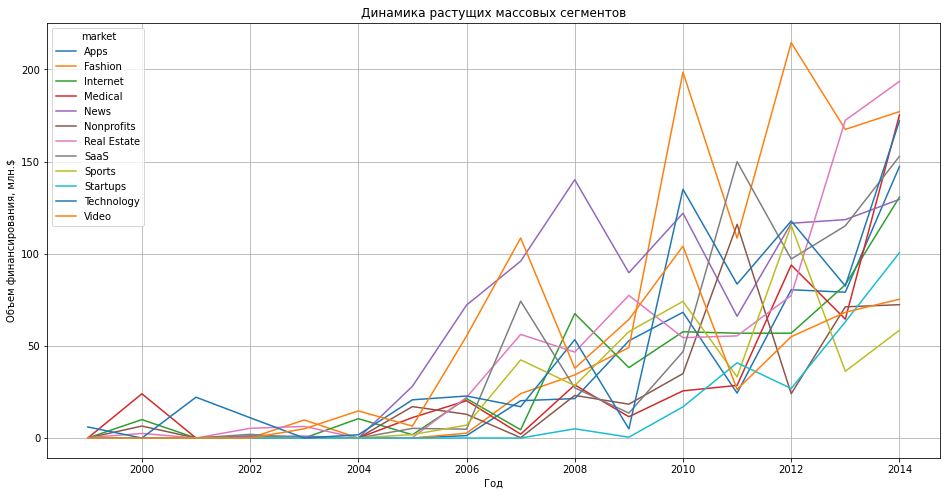

In [49]:
fig, ax = plt.subplots(figsize=(16, 8))

#Создаем график на основе транспонированной сводной таблицы
filtered.T.plot(ax=ax) 
ax.set_title('Динамика растущих массовых сегментов')
ax.set_xlabel('Год')
ax.set_ylabel('Объем финансирования, млн.$')
ax.grid()


plt.show()

Почти все сегменты показывают общую тенденцию к росту на протяжении всего периода, но с большой волатильностью (особенно в 2011 году)
Анализ отдельных сегментов:

Fashion (оранжевая линия): Он показывает два пика: один в 2010 году и еще более высокий в 2012-м. Несмотря на спад в 2013-м, он остается одним из лидеров по объему. Это говорит о высоком интересе инвесторов, но и о высокой нестабильности.

News (фиолетовая линия): Этот сегмент показывает очень уверенный и сильный рост, особенно с 2006 по 2010 год, достигая пика. После этого он стабилизировался на высоком уровне и снова начал расти в 2014-м. Это выглядит как зрелый, стабильно растущий рынок.

Real Estate (розовая линия): Этот сегмент начал активно расти в 2011 год и показывает самый уверенный и почти непрерывный рост, достигая максимума к 2014 году

SaaS (серая линия): Показывает стабильный, уверенный рост на протяжении многих лет, без резких провалов. В 2014 году также демонстрирует хороший рост.

Не могу понять почему активнее других рос в 2010 и 2012, может быть я где то допустил ошибку? Может ли это быть связано с тем, что я делал трансформацию строк и столбцов сводной таблицы для графика?

И подскажи пожалуйста как можно было бы сделать график более читаемым, чтобы линии не так заметно накладывались друг на друга

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

In [ ]:
# Группируем данные по годам и суммируем инвестиции по каждому типу
investments_by_year = df_inv.groupby('mid_funding_year')[['seed', 'venture', 'equity_crowdfunding', 
                                             'undisclosed', 'convertible_note', 'debt_financing', 
                                             'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                                             'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum()

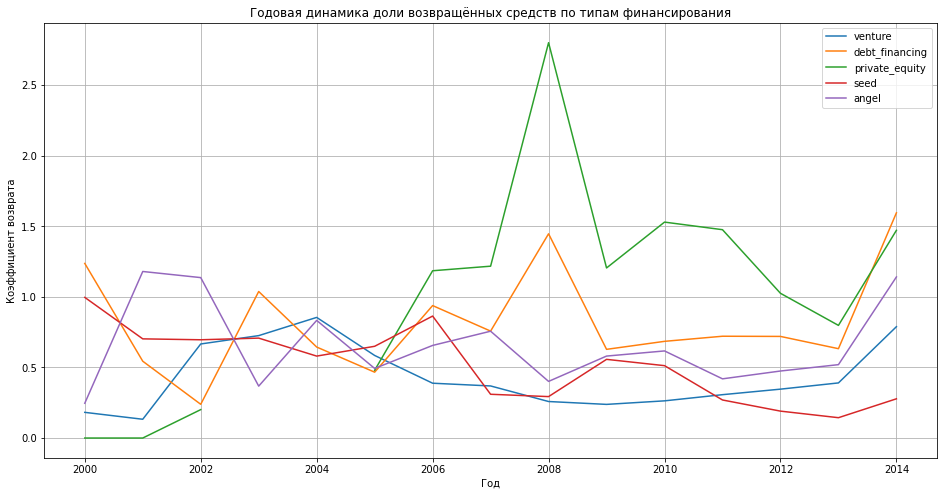

In [51]:
#Приводим года в новом Series к целому числу для соответствия со вторым датафреймом
investments_by_year.index = investments_by_year.index.astype(int)
#Приводим значения во втором датафрейме из миллионов в единицы долларов
returns_by_year = df_ret * 1000000

#Создаем переменную с долями
ratio_df = returns_by_year/(investments_by_year + 1e-60)

#Заполняем выбросы пропусками
ratio_df[ratio_df >3]  = pd.NA
#Выводим нужные столбцы в переменную
final_ratio_df = ratio_df[['venture', 'debt_financing', 'private_equity', 'seed', 'angel']]
#Рисуем график
fig, ax = plt.subplots(figsize=(16, 8))
final_ratio_df.plot(ax=ax)
plt.title('Годовая динамика доли возвращённых средств по типам финансирования')
plt.xlabel('Год')
plt.ylabel('Коэффициент возврата')
plt.grid()
plt.show()


График показывает высокую волатильность доли возврата по всем типам финансирования. Однако, в последние годы (2012-2014) наиболее устойчивый и явный рост показателя доли возврата демонстрируют венчурное (venture) и долговое (debt_financing) финансирование. Это говорит о том, что эти типы инвестиций начали приносить более стабильную отдачу к концу рассматриваемого периода.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



### Обзор проделанной работы
В ходе проекта был проведен комплексный анализ данных, включающий следующие этапы:

**Предобработка данных**
Очистка от дубликатов и пропусков, приведение данных к корректным типам.
**Инжиниринг признаков** 
Компании были разделены на группы по длительности финансирования, а рынки — на массовые, средние и нишевые.
**Анализ выбросов**
Были определены и исключены компании с аномальными объемами финансирования для более точного анализа типичных тенденций.
**Динамический анализ**
Проанализирована динамика объемов и количества раундов по годам, а также рост отдельных сегментов рынка.
Анализ возврата инвестиций: Рассчитана и проанализирована годовая динамика доли возвращенных средств по основным типам финансирования.

#### Ключевые выводы анализа
Неравномерность распределения капитала: Большинство стартапов (около 60%) получают только один раунд финансирования. Однако основной капитал (более 62%) концентрируется в компаниях, которые финансируются дольше года. Это говорит о том, что инвесторы предпочитают вкладывать крупные суммы в уже проверенные, долгосрочные проекты.

**Тенденции 2014 года**
В 2014 году наблюдалось снижение общего количества инвестиционных раундов по сравнению с пиковым 2013 годом. При этом средний (медианный) размер одного раунда, наоборот, показал небольшой рост. Это указывает на то, что рынок становился более зрелым: инвесторы действовали осторожнее, предпочитая вкладывать большие суммы в меньшее число более качественных компаний.

**Перспективные сегменты рынка**
Fashion. Показывает два пика в 2010 году и в 2012-м. Остается одним из лидеров по объему. Это говорит о высоком интересе инвесторов, но и о высокой нестабильности.

News. Этот сегмент показывает очень уверенный и сильный рост. После этого он стабилизировался на высоком уровне и снова начал расти в 2014-м. Это выглядит как зрелый, стабильно растущий рынок.

Real Estate. Этот сегмент начал активно расти в 2011 год и показывает самый уверенный и почти непрерывный рост

SaaS. Показывает стабильный, уверенный рост на протяжении многих лет, без резких провалов.

**Эффективность типов финансирования**

Venture (венчурные инвестиции) являются основным инструментом на рынке как по частоте использования, так и по суммарному объему вложений.
Seed (посевные) и Angel (ангельские) инвестиции очень популярны, но характеризуются небольшими чеками, что типично для ранних стадий.
Private Equity (прямые частные инвестиции) — инструмент для редких, но очень крупных сделок на более поздних стадиях.

**Динамика возврата инвестиций**:
Несмотря на высокую волатильность, к 2014 году наиболее устойчивый рост доли возврата средств показывали венчурное (venture) и долговое (debt_financing) финансирование. Это говорит о том, что эти механизмы начали показывать свою эффективность.

### Рекомендации для инвестора на 2015 год

1. В какую отрасль инвестировать?
Основной фокус — на быстрорастущие массовые сегменты:

Real Estate (Недвижимость): Этот сегмент показал самый уверенный рост в последние годы. Инвестиции в технологические стартапы в этой сфере (PropTech) являются крайне перспективными.
SaaS (ПО как услуга): Этот рынок демонстрирует долгосрочный и стабильный рост без резких провалов. Это фундаментальное направление, которое продолжит быть востребованным.

Дополнительный фокус (сбалансированный подход):

Apps (Приложения): Сегмент продолжает расти и остается привлекательным, особенно в нишах, где еще нет явных лидеров.
News - зрелый и стабильно растущий рынок.

2. Какой тип финансирования использовать?
Основной инструмент — венчурные инвестиции (venture):

Для инвестиций в отобранные растущие сегменты (Real Estate, SaaS) рекомендуется использовать преимущественно венчурный тип финансирования. Этот тип показывает растущую долю возврата средств.

Для диверсификации :

Использовать посевные (seed) и ангельские (angel) инвестиции для вложений небольших сумм в перспективные стартапы на самых ранних стадиях. 

Итоговая рекомендация: На 2015 год наиболее целесообразной выглядит стратегия концентрированных венчурных инвестиций в технологические компании из секторов Real Estate и SaaS, которые уже имеют продукт и показывают рост, с дополнительным использованием небольших посевных и ангельских раундов для поиска новых перспективных проектов.